In [3]:
# Standard library
import os
import sys
import warnings

# adjust path and suppress warnings
sys.path.insert(0, os.path.abspath('..'))
warnings.filterwarnings('ignore')

# Third-party
import numpy as np
import matplotlib.pyplot as plt

from astropy import units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.table import Table

from matplotlib.patches import Circle
from matplotlib.colors import LogNorm

# Local
import util
import utils
import pickle


In [2]:
size_ratio = 1
sub_width, sub_height = size_ratio*10/3, size_ratio*2.8
SMALL_SIZE = 9
MEDIUM_SIZE = 10
BIGGER_SIZE = 11

rc_default = {}
rc_default['font.family'] = 'serif'
rc_default['font.size'] = SMALL_SIZE
rc_default['axes.labelsize'] = MEDIUM_SIZE
rc_default['axes.labelweight'] = 'normal'
rc_default['axes.linewidth'] = 1.0
rc_default['axes.titlesize'] = MEDIUM_SIZE
rc_default['xtick.labelsize'] = SMALL_SIZE
rc_default['ytick.labelsize'] = SMALL_SIZE
rc_default['legend.fontsize'] = SMALL_SIZE
rc_default['figure.titlesize'] = BIGGER_SIZE
rc_default['lines.linewidth'] = 1
rc_default['lines.markersize'] = 4
rc_default['figure.figsize'] = (sub_width, sub_height)
rc_default['savefig.dpi'] = 300

# Latex related
rc_default['text.usetex'] = True
rc_default['mathtext.fontset'] = 'custom'
rc_default['mathtext.rm'] = 'Bitstream Vera Sans'
rc_default['mathtext.it'] = 'Bitstream Vera Sans:italic'
rc_default['mathtext.bf'] = 'Bitstream Vera Sans:bold'

plt.rcParams.update(rc_default)
plt.style.use('tableau-colorblind10')

In [4]:
with open('overdensity_dict_lrg.pkl', 'rb') as f:
    lrg_overdensity = pickle.load(f)
with open('overdensity_dict_bg.pkl', 'rb') as f:
    bg_overdensity = pickle.load(f)

In [5]:
mag_bins = [(7, 11), (11, 12), (12, 13), (13, 16)]

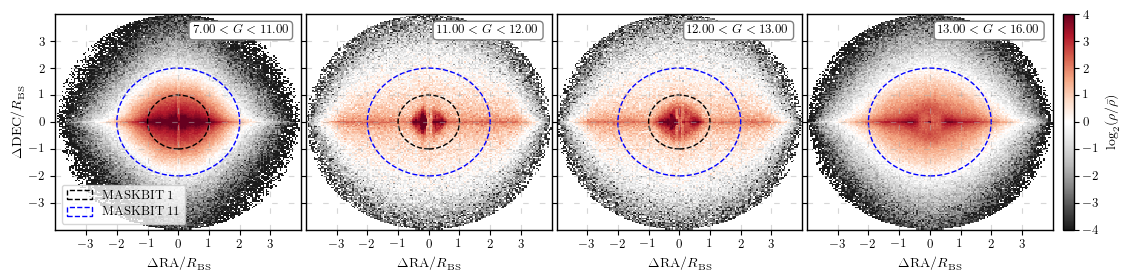

In [8]:
nrows = 1
ncols = 4
fig, axes = plt.subplots(nrows, ncols, sharex=True, sharey=True, num=2, figsize=(sub_width*ncols, sub_height*nrows))
fig.subplots_adjust(hspace=0.02, wspace=0.02)

axes = axes.flatten() if nrows * ncols > 1 else [axes]
for i, mag_bin in enumerate(mag_bins):
    ax = axes[i]

    xe, ye, density_ratio = lrg_overdensity[i]['xe'], lrg_overdensity[i]['ye'], lrg_overdensity[i]['density_ratio']

    mask_radius_lable = ['MASKBIT 1', 'MASKBIT 11']

    pcm = ax.pcolormesh(xe, ye, np.log2(density_ratio), cmap='RdGy_r', vmin=-4, vmax=4)

        # 10. Overplot the DR9 mask circle (R=1) and DR8 mask (R≈2)
    if mag_bin[1]<=13:
        for rad, col in [(1,'k'), (2,'b')]:
            circ = Circle((0,0), radius=rad, fill=False, ls='--', lw=1, ec=col, label=mask_radius_lable[rad-1])
            ax.add_patch(circ)
    else:
        for rad, col in [(2,'b')]:
            circ = Circle((0,0), radius=rad, fill=False, ls='--', lw=1, ec=col,label=mask_radius_lable[rad-1])
            ax.add_patch(circ)
    # 10. Overplot the DR9 mask circle (R=1) and DR8 mask (R≈2)
    
    # for rad, col in [(1,'k'), (2,'b')]:
        # circ = Circle((0,0), radius=rad, fill=False, ls='--', lw=1, ec=col, label=mask_radius_lable[rad-1])
        # ax.add_patch(circ)

    ax.text(
        0.95, 0.95,
        fr"${mag_bin[0]:4.2f}<G<{mag_bin[1]:4.2f}$",
        transform=ax.transAxes,
        verticalalignment='top',
        horizontalalignment='right',
        bbox=dict(
            facecolor='white',
            alpha=1,
            edgecolor='gray',
            boxstyle='round,pad=0.3'
        )
    )
    ax.set_xticks(np.arange(-3, 4, 1))
    ax.set_yticks(np.arange(-3, 4, 1))
    ax.grid(linestyle= (0, (5, 10)), alpha=0.5)
    ax.set_xlim(-4,4)
    ax.set_ylim(-4,4)
    # ax.axhline(0, color='k', lw=1)
    # ax.axvline(0, color='k', lw=1)
    # ax.set_title(f'G mag: {mag_bin[0]} - {mag_bin[1]}')
    # ax.set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
    # ax.set_ylabel(r'$\Delta\mathrm{DEC}/R_{\rm BS}$')
    i += 1
    
axes[0].set_ylabel(r'$\Delta\mathrm{DEC}/R_{\rm BS}$')
axes[0].set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
axes[1].set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
axes[2].set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
axes[3].set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
axes[0].legend(loc='lower left')
# axes[5].set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
# cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
# fig.colorbar(pcm, cax=cax, label=r'$\log_2(\eta/\bar\eta)$')
cbar = fig.colorbar(pcm, ax=axes, fraction=0.025, pad=0.01)
cbar.set_label(r'$\log_2(\rho/\bar\rho)$')
# cbar.ax.tick_params(labelsize=MEDIUM_SIZE)
# plt.tight_layout(rect=[0,0,0.9,1])
# plt.savefig('gaia_mask_LRG_4x1.png', dpi=400, bbox_inches='tight')
# plt.savefig('gaia_mask_LRG_4x1.pdf', dpi=400, bbox_inches='tight')


plt.show()

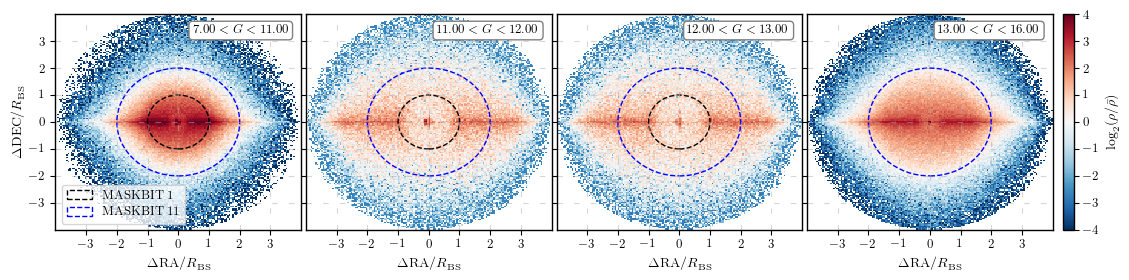

In [ ]:
nrows = 2
ncols = 4
fig, axes = plt.subplots(nrows, ncols, sharex=True, sharey=True, num=2, figsize=(sub_width*ncols, sub_height*nrows))
fig.subplots_adjust(hspace=0.02, wspace=0.02)

axes = axes.flatten() if nrows * ncols > 1 else [axes]
for i, mag_bin in enumerate(mag_bins):
    ax = axes[i]

    xe, ye, density_ratio = bg_overdensity[i]['xe'], bg_overdensity[i]['ye'], bg_overdensity[i]['density_ratio']

    mask_radius_lable = ['MASKBIT 1', 'MASKBIT 11']

    pcm = ax.pcolormesh(xe, ye, np.log2(density_ratio), cmap='RdBu_r', vmin=-4, vmax=4)

        # 10. Overplot the DR9 mask circle (R=1) and DR8 mask (R≈2)
    if mag_bin[1]<=13:
        for rad, col in [(1,'k'), (2,'b')]:
            circ = Circle((0,0), radius=rad, fill=False, ls='--', lw=1, ec=col, label=mask_radius_lable[rad-1])
            ax.add_patch(circ)
    else:
        for rad, col in [(2,'b')]:
            circ = Circle((0,0), radius=rad, fill=False, ls='--', lw=1, ec=col,label=mask_radius_lable[rad-1])
            ax.add_patch(circ)
    # 10. Overplot the DR9 mask circle (R=1) and DR8 mask (R≈2)
    
    # for rad, col in [(1,'k'), (2,'b')]:
        # circ = Circle((0,0), radius=rad, fill=False, ls='--', lw=1, ec=col, label=mask_radius_lable[rad-1])
        # ax.add_patch(circ)

    ax.text(
        0.95, 0.95,
        fr"${mag_bin[0]:4.2f}<G<{mag_bin[1]:4.2f}$",
        transform=ax.transAxes,
        verticalalignment='top',
        horizontalalignment='right',
        bbox=dict(
            facecolor='white',
            alpha=1,
            edgecolor='gray',
            boxstyle='round,pad=0.3'
        )
    )
    ax.set_xticks(np.arange(-3, 4, 1))
    ax.set_yticks(np.arange(-3, 4, 1))
    ax.grid(linestyle= (0, (5, 10)), alpha=0.5)
    ax.set_xlim(-4,4)
    ax.set_ylim(-4,4)
    # ax.axhline(0, color='k', lw=1)
    # ax.axvline(0, color='k', lw=1)
    # ax.set_title(f'G mag: {mag_bin[0]} - {mag_bin[1]}')
    # ax.set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
    # ax.set_ylabel(r'$\Delta\mathrm{DEC}/R_{\rm BS}$')
    i += 1


axes[0].set_ylabel(r'$\Delta\mathrm{DEC}/R_{\rm BS}$')
axes[0].set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
axes[1].set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
axes[2].set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
axes[3].set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
axes[0].legend(loc='lower left')
# axes[5].set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
# cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
# fig.colorbar(pcm, cax=cax, label=r'$\log_2(\eta/\bar\eta)$')
cbar = fig.colorbar(pcm, ax=axes, fraction=0.025, pad=0.01)
cbar.set_label(r'$\log_2(\rho/\bar\rho)$')
# cbar.ax.tick_params(labelsize=MEDIUM_SIZE)
# plt.tight_layout(rect=[0,0,0.9,1])
# plt.savefig('gaia_mask_LRG_4x1.png', dpi=400, bbox_inches='tight')
# plt.savefig('gaia_mask_LRG_4x1.pdf', dpi=400, bbox_inches='tight')


plt.show()

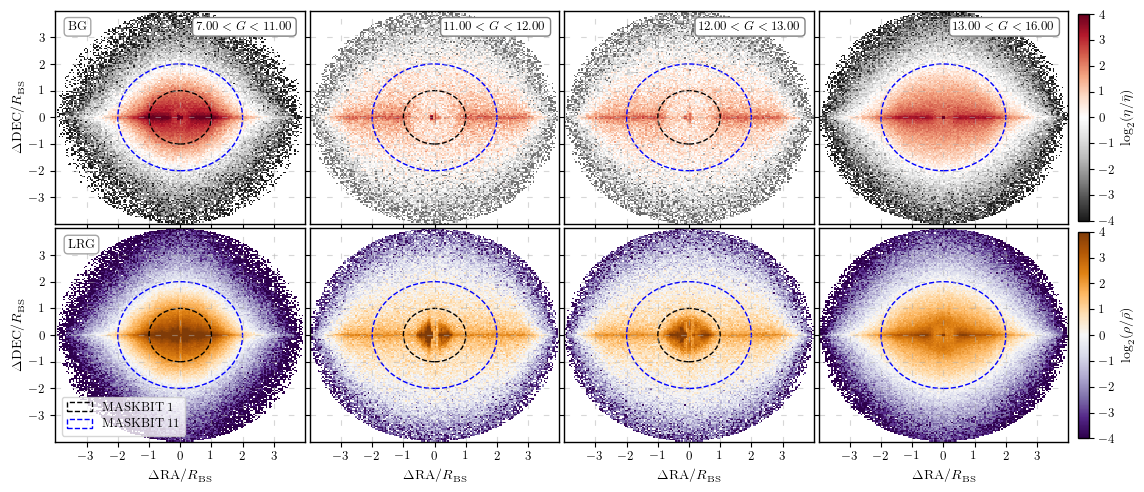

In [50]:
nrows = 2
ncols = 4
fig, axes = plt.subplots(nrows, ncols, sharex=True, sharey=True, num=2, figsize=(sub_width*ncols, sub_height*nrows))
fig.subplots_adjust(hspace=0.02, wspace=0.02)

axes = axes.flatten() if nrows * ncols > 1 else [axes]

for i, mag_bin in enumerate(mag_bins):
    ax = axes[i]

    xe, ye, density_ratio = bg_overdensity[i]['xe'], bg_overdensity[i]['ye'], bg_overdensity[i]['density_ratio']

    mask_radius_lable = ['MASKBIT 1', 'MASKBIT 11']

    pcm_bg = ax.pcolormesh(xe, ye, np.log2(density_ratio), cmap='RdGy_r', vmin=-4, vmax=4)

        # 10. Overplot the DR9 mask circle (R=1) and DR8 mask (R≈2)
    if mag_bin[1]<=13:
        for rad, col in [(1,'k'), (2,'b')]:
            circ = Circle((0,0), radius=rad, fill=False, ls='--', lw=1, ec=col, label=mask_radius_lable[rad-1])
            ax.add_patch(circ)
    else:
        for rad, col in [(2,'b')]:
            circ = Circle((0,0), radius=rad, fill=False, ls='--', lw=1, ec=col,label=mask_radius_lable[rad-1])
            ax.add_patch(circ)
    # 10. Overplot the DR9 mask circle (R=1) and DR8 mask (R≈2)
    
    # for rad, col in [(1,'k'), (2,'b')]:
        # circ = Circle((0,0), radius=rad, fill=False, ls='--', lw=1, ec=col, label=mask_radius_lable[rad-1])
        # ax.add_patch(circ)

    ax.text(
        0.95, 0.95,
        fr"${mag_bin[0]:4.2f}<G<{mag_bin[1]:4.2f}$",
        transform=ax.transAxes,
        verticalalignment='top',
        horizontalalignment='right',
        bbox=dict(
            facecolor='white',
            alpha=1,
            edgecolor='gray',
            boxstyle='round,pad=0.3'
        )
    )
    ax.set_xticks(np.arange(-3, 4, 1))
    ax.set_yticks(np.arange(-3, 4, 1))
    ax.grid(linestyle= (0, (5, 10)), alpha=0.5)
    ax.set_xlim(-4,4)
    ax.set_ylim(-4,4)
    # ax.axhline(0, color='k', lw=1)
    # ax.axvline(0, color='k', lw=1)
    # ax.set_title(f'G mag: {mag_bin[0]} - {mag_bin[1]}')
    # ax.set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
    # ax.set_ylabel(r'$\Delta\mathrm{DEC}/R_{\rm BS}$')
    i += 1

for i, mag_bin in enumerate(mag_bins):
    ax = axes[i+4]

    xe, ye, density_ratio = lrg_overdensity[i]['xe'], lrg_overdensity[i]['ye'], lrg_overdensity[i]['density_ratio']

    mask_radius_lable = ['MASKBIT 1', 'MASKBIT 11']

    pcm_lrg = ax.pcolormesh(xe, ye, np.log2(density_ratio), cmap='PuOr_r', vmin=-4, vmax=4)

        # 10. Overplot the DR9 mask circle (R=1) and DR8 mask (R≈2)
    if mag_bin[1]<=13:
        for rad, col in [(1,'k'), (2,'b')]:
            circ = Circle((0,0), radius=rad, fill=False, ls='--', lw=1, ec=col, label=mask_radius_lable[rad-1])
            ax.add_patch(circ)
    else:
        for rad, col in [(2,'b')]:
            circ = Circle((0,0), radius=rad, fill=False, ls='--', lw=1, ec=col,label=mask_radius_lable[rad-1])
            ax.add_patch(circ)
    # 10. Overplot the DR9 mask circle (R=1) and DR8 mask (R≈2)
    
    # for rad, col in [(1,'k'), (2,'b')]:
        # circ = Circle((0,0), radius=rad, fill=False, ls='--', lw=1, ec=col, label=mask_radius_lable[rad-1])
        # ax.add_patch(circ)

    # ax.text(
    #     0.95, 0.95,
    #     fr"${mag_bin[0]:4.2f}<G<{mag_bin[1]:4.2f}$",
    #     transform=ax.transAxes,
    #     verticalalignment='top',
    #     horizontalalignment='right',
    #     bbox=dict(
    #         facecolor='white',
    #         alpha=1,
    #         edgecolor='gray',
    #         boxstyle='round,pad=0.3'
    #     )
    # )
    ax.set_xticks(np.arange(-3, 4, 1))
    ax.set_yticks(np.arange(-3, 4, 1))
    ax.grid(linestyle= (0, (5, 10)), alpha=0.5)
    ax.set_xlim(-4,4)
    ax.set_ylim(-4,4)
    # ax.axhline(0, color='k', lw=1)
    # ax.axvline(0, color='k', lw=1)
    # ax.set_title(f'G mag: {mag_bin[0]} - {mag_bin[1]}')
    # ax.set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
    # ax.set_ylabel(r'$\Delta\mathrm{DEC}/R_{\rm BS}$')
    i += 1



axes[0].text(
    0.05, 0.95,
    fr"BG",
    transform=axes[0].transAxes,
    verticalalignment='top',
    horizontalalignment='left',
    bbox=dict(
        facecolor='white',
        alpha=0.7,
        edgecolor='gray',
        boxstyle='round,pad=0.3'
    )
)

axes[4].text(
    0.05, 0.95,
    fr"LRG",
    transform=axes[4].transAxes,
    verticalalignment='top',
    horizontalalignment='left',
    bbox=dict(
        facecolor='white',
        alpha=0.7,
        edgecolor='gray',
        boxstyle='round,pad=0.3'
    )
)

axes[0].set_ylabel(r'$\Delta\mathrm{DEC}/R_{\rm BS}$')
axes[4].set_ylabel(r'$\Delta\mathrm{DEC}/R_{\rm BS}$')

axes[4].set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
axes[5].set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
axes[6].set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
axes[7].set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')

axes[4].legend(loc='lower left')
# axes[5].set_xlabel(r'$\Delta\mathrm{RA}/R_{\rm BS}$')
# cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
# fig.colorbar(pcm, cax=cax, label=r'$\log_2(\eta/\bar\eta)$')
cbar = fig.colorbar(pcm_lrg, ax=axes[4:], fraction=0.01, pad=0.01)
cbar.set_label(r'$\log_2(\rho/\bar\rho)$')
cbar_bg = fig.colorbar(pcm_bg, ax=axes[:4], fraction=0.01, pad=0.01)
cbar_bg.set_label(r'$\log_2(\eta/\bar\eta)$')
# cbar.ax.tick_params(labelsize=MEDIUM_SIZE)
# plt.tight_layout(rect=[0,0,0.9,1])
plt.savefig('gaia_mask_both_4x2.png', dpi=400, bbox_inches='tight')
plt.savefig('gaia_mask_both_4x2.pdf', dpi=400, bbox_inches='tight')


plt.show()